In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qutip as qt
from qudit_nh_design import *

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


In [3]:
Q = np.zeros([3,3])
Q[2,2]=1
Q=qt.Qobj(Q)
P=1-Q
print(P,Q)

Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 0.]] Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[0. 0. 0.]
 [0. 0. 0.]
 [0. 0. 1.]]


## 1 - Three examples of non-Hermitian dynamics
### 1.1 - Single steady-state, high entropy

In [2]:
N=2
h, J, Omega= 1,5.3, 2*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1])
psi0_eff = qt.basis([2]*N,n=[0,1])

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

effective paramters: lambda_1=0.00-0.20j, lambda_2=0.00-0.70j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.]


In [137]:
res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

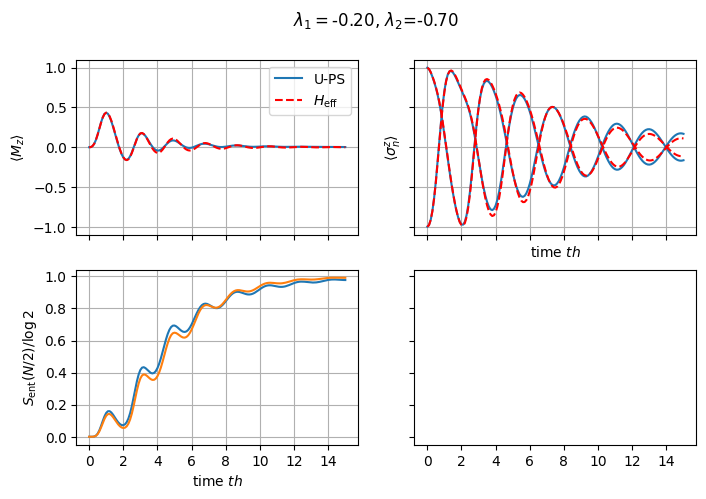

In [142]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,res.expect[0],label='U-PS',c='C0')
ax[0,1].plot(tvec,res.expect[1],label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,res2.expect[0],'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,res2.expect[1],'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[0])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[0])/np.log(2))
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log 2$')

#ax[1,1].plot(tvec[1:],np.cumsum(1-np.array(res.measurement_outcomes[1:]))) 
'''
plt.plot(tvec,res.expect[0])
plt.plot(tvec,res.expect[1])

plt.plot(trand,res_rand.expect[0],'-.')
plt.plot(trand,res_rand.expect[1],'-.')

plt.plot(tvec,res2.expect[0],'--')
plt.plot(tvec,res2.expect[1],'--')
plt.xlabel(r"time $t h_x$")
'''
fig.savefig('N2_entangled.pdf',bbox_inches='tight')

### 1.2 Doubly degenerate steady state.

In [3]:
N=2
h, J, Omega= 1,7.2, 5.3
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1])
psi0_eff = qt.basis([2]*N,n=[0,1])

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-0.70j, lambda_2=0.00-1.30j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.]


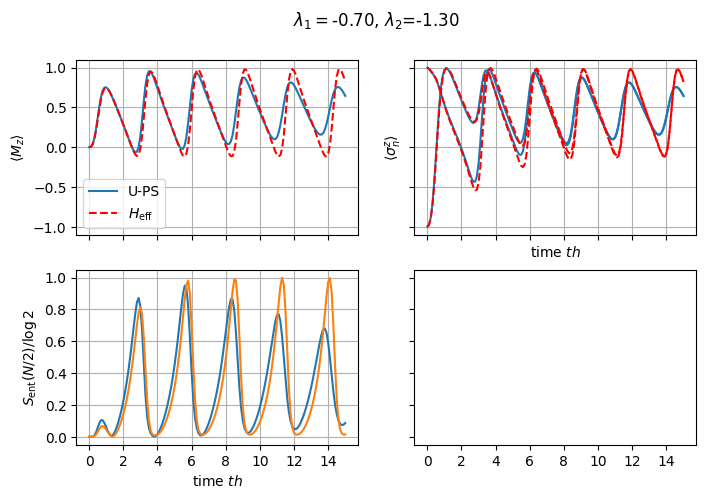

In [133]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,res.expect[0],label='U-PS',c='C0')
ax[0,1].plot(tvec,res.expect[1],label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,res2.expect[0],'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,res2.expect[1],'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[0])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[0])/np.log(2))
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log 2$')
fig.savefig('N2_oscillatory.pdf',bbox_inches='tight')

### 1.3 Single steady state, low entropy

In [134]:
N=2
h, J, Omega= 1,3.5, 5.1*np.sqrt(2)
tf = 15
nstep = 150
tvec = np.linspace(0,tf,nstep+1)
rate = nstep/tf
trand = poisson_times(tf,rate)

#--- full Hamiltonian with measurements
single_body_terms = [[h, ('x', 0, 1), None],[Omega, ('x', 1, 2), None] ]
two_body_terms=[[J,('x', 1, 2), ('x', 1, 2)]]
H_qutrit = build_hamiltonian(N,single_body_terms, two_body_terms)

#--- target effective Hamiltonian
heff, lambda1, lambda2 = h, -1j*Omega**2/rate/4, -1j*J**2/rate/4
print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)

print(H_qutrit.isherm,H_qeff.isherm)
psi0 = qt.basis([3]*N,n=[0,1])
psi0_eff = qt.basis([2]*N,n=[0,1])

Z01 = embedded_pauli('z',0,1)
print(Z01)
e_evo = [embed_on_site(Z01,j,N) for j in range(N)]
e_evo_eff = [embed_on_site(qt.sigmaz(),j,N,d=2) for j in range(N)]
print(qt.expect(e_evo,psi0))
options={'progress':False}

res = time_evo(H_qutrit,psi0,tvec,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options=options)

res_rand = time_evo(H_qutrit,psi0,trand,P,N,measured_sites=[j for j in range(N)],e_ops=e_evo, 
               force_proj=True,options={'uniform_dt':False, 'progress':False})

res2 = time_evo(H_qeff,psi0_eff,tvec,P,N,measured_sites=[],e_ops=e_evo_eff, options=options)

effective paramters: lambda_1=0.00-1.30j, lambda_2=0.00-0.31j
True False
Quantum object: dims=[[3], [3]], shape=(3, 3), type='oper', dtype=Dense, isherm=True
Qobj data =
[[ 1.  0.  0.]
 [ 0. -1.  0.]
 [ 0.  0.  0.]]
[ 1. -1.]


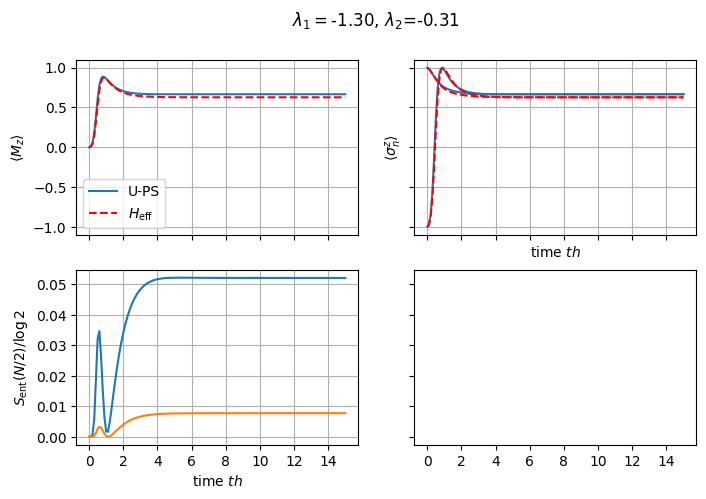

In [135]:

fig,ax = plt.subplots(nrows=2,ncols=2,sharex=True, sharey='row')
fig.set_size_inches([8,5])
fig.suptitle(rf"$\lambda_1=${lambda1.imag:.2f}, $\lambda_2$={lambda2.imag:.2f}")
ax[0,0].plot(tvec,sum(res.expect)/2,label='U-PS')
#ax[0].plot(trand,sum(res_rand.expect)/2,'g-.',label='R-PS')
ax[0,0].plot(tvec,sum(res2.expect)/2,'r--',label=r'$H_{\rm eff}$')
ax[1,0].set_xlabel(r'time $t h$')
ax[0,0].set_ylabel(r'$\langle M_z \rangle$')
ax[0,0].legend()
ax[0,0].grid()
ax[0,0].set_xticks(np.arange(0,16,2))

ax[0,1].grid()
ax[0,1].plot(tvec,res.expect[0],label='U-PS',c='C0')
ax[0,1].plot(tvec,res.expect[1],label='U-PS',c='C0')
#ax[1].plot(trand,res_rand.expect[0],'g-.',label='R-PS')
#ax[1].plot(trand,res_rand.expect[1],'g-.',label='R-PS')
ax[0,1].plot(tvec,res2.expect[0],'r--',label=r'$H_{\rm eff}$')
ax[0,1].plot(tvec,res2.expect[1],'r--',label=r'$H_{\rm eff}$')
ax[0,1].set_xlabel(r'time $t h$')
ax[0,1].set_ylabel(r'$\langle \sigma^z_n \rangle$')



ax[1,0].plot(tvec,get_entanglement(res.states,[0])/np.log(2))
ax[1,0].plot(tvec,get_entanglement(res2.states,[0])/np.log(2))
ax[1,0].grid()
ax[1,0].set_ylabel(r'$S_{\rm ent}(N/2)/\log 2$')

fig.savefig('N2_separable.pdf',bbox_inches='tight')

## 2 - Phase diagram

In [5]:
N = 2
h=1
ns=60
lambda1_list=np.linspace(0.01,1.5,ns)
lambda2_list=np.linspace(0.01,1.5,ns)
gs_multiplicity = []
gs_entropy = []
for lam1 in lambda1_list:
    for lam2 in lambda2_list:
        heff, lambda1, lambda2 = h, -1j*lam1, -1j*lam2
        #print(f"effective paramters: lambda_1={lambda1:.2f}, lambda_2={lambda2:.2f}")
        single_body_eff = [[heff, ('x', 0, 1), None], [2*lambda1, ('p-', 0, 1), None] ]
        two_body_eff=[[2*lambda2,('p-', 0, 1), ('p-', 0, 1)]]
        H_qeff = build_hamiltonian(N,single_body_eff, two_body_eff,d=2)
        res = nh_stationary_states(H_qeff,N, tol=1e-8,d=2)
        gs_multiplicity.append(res.degeneracy)
        gs_entropy.append(np.array(res.entanglement_entropies).mean())        

Text(0.5, 1.0, '$S_{\\rm ent}(N/2)$')

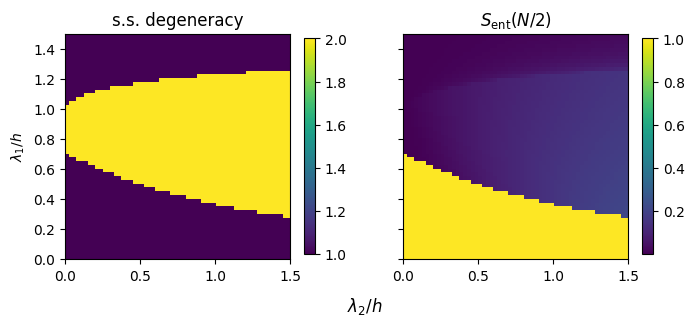

In [19]:
fig, ax = plt.subplots(ncols=2,sharex=True, sharey=True)
fig.set_size_inches([8,3.5])
fig.supxlabel(r'$\lambda_2/h$')
ax[0].set_ylabel(r'$\lambda_1/h$')
im=ax[0].imshow(np.array(gs_multiplicity).reshape([ns,ns]),origin='lower', extent=[0,1.5,0,1.5])
fig.colorbar(im,ax=ax[0],shrink=0.8)
ax[0].set_title('s.s. degeneracy')
im=ax[1].imshow(np.array(gs_entropy).reshape([ns,ns])/np.log(2),origin='lower', extent=[0,1.5,0,1.5])
fig.colorbar(im,ax=ax[1],shrink=0.8)
ax[1].set_title(r'$S_{\rm ent}(N/2)$')

